# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/m-awaischohan/flyrank-internship-ml/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

**Research question (Lane 4, CTR / engagement opportunity scoring):** *Which already-visible pages earn a much lower click-through rate than their search position normally earns, and are likely to stay that way, so a reviewer should open them first?*

**Decision it supports:** a content reviewer has time for about 50 pages a week. The output is a ranked review queue, not an automatic change. The cost of a wrong call is wasted reading time, which is why the evaluation is precision at the top of the list.

**Unit:** one page. **Output:** a ranking score between 0 and 1. **Human action:** open the live search result, check the snippet and the page, decide to act, wait or reject.

**Label (a proxy, not a result of any fix):** `low_later` = the page's CTR in the later 30 days is under half of its position band's typical CTR in that same window. Pages need at least 100 impressions in each window.

This notebook is the single source for the paper: it recomputes every number and writes the figures and a metrics file the paper is built from.

In [1]:
import os, sys, subprocess, json, warnings
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from sklearn.model_selection import GroupKFold, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
import sklearn
warnings.filterwarnings("ignore")
SEED = 42

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/m-awaischohan/flyrank-internship-ml"
REPO_DIR = "flyrank-internship-ml"
if IN_COLAB:
    if os.path.basename(os.getcwd()) != REPO_DIR:
        if not os.path.isdir(REPO_DIR):
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
        os.chdir(REPO_DIR)
else:
    while not os.path.isdir("data/raw") and os.getcwd() != "/":
        os.chdir("..")
os.makedirs("work/outputs", exist_ok=True); os.makedirs("work/figures", exist_ok=True)
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| seed", SEED)
M = {"environment": {"scikit_learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__, "seed": SEED}}

python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | seed 42


## 2. Data

**Source:** the anonymized starter file of the FlyRank ML Internship dataset (`data/raw/content_refresh_anonymized.csv`): one row per content page, trailing-90-day search and analytics totals plus an earlier-30-day and a later-30-day split, pseudonymous page and client ids. **All results in this paper use only this file.** I describe the larger hosted warehouse release in my data-contract notebook, but no number here comes from it.

**Scope (what is kept):** pages with at least 100 impressions in the earlier 30 days and an average position between 1 and 20 (`avg_position = 0` means "no data" and is dropped). **Label population:** pages that also kept at least 100 impressions in the later 30 days. Pages that vanished are therefore not in the evaluation, and the paper says so.

**Excluded as features, and why:** the label window (`*_last_30d`), the trend columns (the label source for another question), the 90-day totals and rates (they contain the later 30 days), `days_since_last_update` (an update inside the later window happens after the prediction), and the pseudonymous ids (grouping only).

In [2]:
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
BANDS = [0, 3, 6, 10, 15, 20]; BAND_LABELS = ["1-3", "4-6", "7-10", "11-15", "16-20"]

el = df[(df["impressions_prev_30d"] >= 100) & (df["avg_position"] > 0) & (df["avg_position"] <= 20)].copy().reset_index(drop=True)
el["band"] = pd.cut(el["avg_position"], BANDS, labels=BAND_LABELS)
el["ctr_prev"] = 100 * el["clicks_prev_30d"] / el["impressions_prev_30d"]
el["labelled"] = el["impressions_last_30d"] >= 100
el["ctr_last"] = 100 * el["clicks_last_30d"] / el["impressions_last_30d"]
lt = el[el["labelled"]].groupby("band", observed=True)[["clicks_last_30d", "impressions_last_30d"]].sum()
typ_last = 100 * lt["clicks_last_30d"] / lt["impressions_last_30d"]
el["y"] = np.where(el["labelled"], (el["ctr_last"] < 0.5 * el["band"].map(typ_last).astype(float)).astype(float), np.nan)

lab = el[el["labelled"]]
dropped = el[~el["labelled"]]
big_client = lab["client_id"].value_counts().index[0]
M["data"] = {
    "rows": int(len(df)), "columns": int(df.shape[1]), "clients_total": int(df["client_id"].nunique()),
    "no_position_rows": int((df["avg_position"] == 0).sum()),
    "eligible_pages": int(len(el)), "labelled_pages": int(len(lab)), "clients_labelled": int(lab["client_id"].nunique()),
    "dropped_share": round(float(len(dropped) / len(el)), 3),
    "median_earlier_impressions_kept": float(lab["impressions_prev_30d"].median()),
    "median_earlier_impressions_dropped": float(dropped["impressions_prev_30d"].median()),
    "base_rate": round(float(lab["y"].mean()), 3),
    "largest_client_share": round(float((lab["client_id"] == big_client).mean()), 3),
    "base_rate_without_largest_client": round(float(lab.loc[lab["client_id"] != big_client, "y"].mean()), 3),
    "later_band_norm_pct": {k: round(float(v), 3) for k, v in typ_last.items()},
}
d = M["data"]
print(f"Starter file: {d['rows']:,} rows x {d['columns']} columns, {d['clients_total']} clients ({d['no_position_rows']:,} rows with no position data)")
print(f"In scope (>=100 earlier impressions, position 1-20): {d['eligible_pages']:,} pages")
print(f"With a label (>=100 later impressions): {d['labelled_pages']:,} pages from {d['clients_labelled']} clients; {d['dropped_share']:.1%} of in-scope pages dropped")
print(f"  median earlier impressions: kept {d['median_earlier_impressions_kept']:,.0f} vs dropped {d['median_earlier_impressions_dropped']:,.0f}")
print(f"Base rate of low_later: {d['base_rate']:.3f} | largest client = {d['largest_client_share']:.0%} of labelled pages (base rate without it {d['base_rate_without_largest_client']:.3f})")

Starter file: 30,000 rows x 44 columns, 32 clients (1,205 rows with no position data)
In scope (>=100 earlier impressions, position 1-20): 12,770 pages
With a label (>=100 later impressions): 11,111 pages from 29 clients; 13.0% of in-scope pages dropped
  median earlier impressions: kept 1,182 vs dropped 165
Base rate of low_later: 0.410 | largest client = 39% of labelled pages (base rate without it 0.363)


## 3. Methodology

**Baseline (frozen, Week 4):** compare a page's earlier-30-day CTR with the typical CTR of its position band. Flag it if it is under half of that norm *and* at least 10 clicks were expected; the score is the **missing clicks** (expected minus actual). Nothing in it is tuned in this paper.

**Models:** logistic regression (the one I can explain), gradient boosting (depth 3, a check), and their average, which is the review queue's score. All use 17 features known before the label window.

**Validation:** 5-fold **grouped by client**, so every page is scored by a model that never saw its client. Position-band norms are recomputed from training clients only. The data holds two 30-day windows only, so a time-aware split is not possible; I test "a new client", not "a new month".

**Measure:** precision@K, the share of the top K pages that really were low later, always next to the base rate; AUC as the discrimination number.

**Leakage checks:** a feature-by-feature timeline audit, then four tests (drop each suspect, add the excluded `days_since_last_update`, add a deliberate leak that must push the score to 1.0, and shuffle the labels, which must give about 0.5).

In [3]:
# ---- features: earlier window + fixed page properties only
el["log_imp"] = np.log1p(el["impressions_prev_30d"]); el["log_clk"] = np.log1p(el["clicks_prev_30d"])
el["log_sess"] = np.log1p(el["sessions_prev_30d"])
el["has_wc"] = el["word_count"].notna().astype(int); el["wc"] = el["word_count"].fillna(0)
el["has_kw"] = el["search_volume"].notna().astype(int); el["log_sv"] = np.log1p(el["search_volume"].fillna(0))
for v in ["informational", "transactional", "commercial"]:
    el["int_" + v] = (el["main_intent"] == v).astype(int)
el["is_kw_article"] = (el["content_type"] == "keyword article").astype(int)
STATIC = ["log_imp", "log_clk", "ctr_prev", "avg_position", "log_sess", "content_age_days", "has_wc", "wc",
          "has_kw", "log_sv", "int_informational", "int_transactional", "int_commercial", "is_kw_article"]
RELATIVE = ["ratio", "gap", "miss"]
FEATURES = STATIC + RELATIVE
assert not [c for c in FEATURES if "last_30d" in c or c.startswith("trend_") or c in ("ctr", "days_since_last_update", "client_id", "content_id")]
el["ctr_last_feature"] = el["ctr_last"].fillna(0).replace([np.inf, -np.inf], 0); el["dsu"] = el["days_since_last_update"]      # ONLY for the leakage tests

def band_typical(train):
    g = train.groupby("band", observed=True)[["clicks_prev_30d", "impressions_prev_30d"]].sum()
    return 100 * g["clicks_prev_30d"] / g["impressions_prev_30d"]

def add_relative(d, typical):
    d = d.copy()
    d["typ"] = d["band"].map(typical).astype(float)
    d["ratio"] = d["ctr_prev"] / d["typ"]; d["gap"] = d["ctr_prev"] - d["typ"]
    d["expected"] = d["impressions_prev_30d"] * d["typ"] / 100
    d["miss"] = d["expected"] - d["clicks_prev_30d"]
    return d

# ---- folds: grouped by client (identical to Weeks 5-7) and a random split for the "before" comparison
ev0 = el[el["labelled"]].reset_index(drop=True)
client_fold = {}
for f, (_, te) in enumerate(GroupKFold(n_splits=5).split(ev0, ev0["y"], ev0["client_id"])):
    for c in ev0.iloc[te]["client_id"].unique():
        client_fold[c] = f
el["fold"] = el["client_id"].map(client_fold)
lab_idx = np.where(el["labelled"])[0]
group_splits = [(np.where(el["labelled"] & (el["fold"] != f))[0], np.where(el["fold"] == f)[0]) for f in range(5)]
rand_splits = [(lab_idx[tr], lab_idx[te]) for tr, te in KFold(n_splits=5, shuffle=True, random_state=SEED).split(lab_idx)]

def run_design(splits, norms, features=FEATURES, label=None):
    '''Out-of-fold scores (NaN where a page was not in any test set) for the rule, LR and boosting.'''
    yy = el["y"].values if label is None else label
    out = {m: np.full(len(el), np.nan) for m in ("rule", "logreg", "gboost")}
    for tr, te in splits:
        typical = band_typical(el) if norms == "all" else band_typical(el.iloc[tr])
        a, b = add_relative(el.iloc[tr], typical), add_relative(el.iloc[te], typical)
        out["rule"][te] = np.where((b["ratio"] < 0.5) & (b["expected"] >= 10), b["miss"], 0.0)
        lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000)).fit(a[features], yy[tr])
        out["logreg"][te] = lr.predict_proba(b[features])[:, 1]
        gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED).fit(a[features], yy[tr])
        out["gboost"][te] = gb.predict_proba(b[features])[:, 1]
    out["blend"] = (out["logreg"] + out["gboost"]) / 2
    return out

ids = el["content_id"].values
def prec(score, k, mask, label=None):
    yy = el["y"].values if label is None else label
    idx = np.where(mask & ~np.isnan(score))[0]
    order = idx[np.lexsort((ids[idx], -score[idx]))]
    return round(float(yy[order[:k]].mean()), 3)
def auc(score, mask, label=None):
    yy = el["y"].values if label is None else label
    idx = np.where(mask & ~np.isnan(score))[0]
    return round(float(roc_auc_score(yy[idx], score[idx])), 3)
LAB = el["labelled"].values
print(f"{len(FEATURES)} features:", ", ".join(FEATURES))

17 features: log_imp, log_clk, ctr_prev, avg_position, log_sess, content_age_days, has_wc, wc, has_kw, log_sv, int_informational, int_transactional, int_commercial, is_kw_article, ratio, gap, miss


In [4]:
# ---- leakage audit: the timeline table, then the four tests (grouped design, gradient boosting)
audit = pd.DataFrame([
    ("log_imp, log_clk, ctr_prev, log_sess", "earlier 30 days", "OK"),
    ("ratio, gap, miss", "earlier-30-day CTR vs band norm from TRAINING clients", "OK"),
    ("avg_position", "90-day average, overlaps the later 30 days", "WATCH: tested below"),
    ("content_age_days, word count, keyword and intent fields, content type", "fixed page properties (missing values flagged, not zero-filled)", "OK"),
    ("days_since_last_update", "update date at export time", "EXCLUDED: may fall after the prediction"),
    ("trend_direction, trend_pct", "label source for another question", "EXCLUDED"),
    ("*_90d totals, ctr, engagement, scroll, ai_*", "90-day windows containing the later 30 days", "EXCLUDED"),
    ("*_last_30d", "the label window", "EXCLUDED"),
    ("content_id, client_id", "pseudonyms", "EXCLUDED: grouping only"),
], columns=["feature(s)", "window / source", "verdict"])
print(audit.to_string(index=False))

rng = np.random.default_rng(SEED)
shuffled = el["y"].values.copy(); shuffled[LAB] = rng.permutation(shuffled[LAB])
variants = {
    "final features (reference)": (FEATURES, None),
    "drop avg_position": ([f for f in FEATURES if f != "avg_position"], None),
    "drop band-norm features (ratio, gap, miss)": (STATIC, None),
    "add days_since_last_update": (FEATURES + ["dsu"], None),
    "add ctr_last (deliberate leak)": (FEATURES + ["ctr_last_feature"], None),
    "shuffled labels": (FEATURES, shuffled),
}
leak = {}
for name, (feats, labl) in variants.items():
    s = run_design(group_splits, "train", features=feats, label=labl)["gboost"]
    leak[name] = {"auc": auc(s, LAB, labl), "p50": prec(s, 50, LAB, labl), "p100": prec(s, 100, LAB, labl)}
M["leakage"] = leak
print("\nLeakage tests (gradient boosting, grouped by client):")
pd.DataFrame(leak).T

                                                           feature(s)                                                 window / source                                 verdict
                                 log_imp, log_clk, ctr_prev, log_sess                                                 earlier 30 days                                      OK
                                                     ratio, gap, miss           earlier-30-day CTR vs band norm from TRAINING clients                                      OK
                                                         avg_position                      90-day average, overlaps the later 30 days                     WATCH: tested below
content_age_days, word count, keyword and intent fields, content type fixed page properties (missing values flagged, not zero-filled)                                      OK
                                               days_since_last_update                                      update date at export t

,auc,p50,p100
final features (reference),0.788,1.00,0.92
drop avg_position,0.784,0.98,0.92
"drop band-norm features (ratio, gap, miss)",0.786,1.00,0.93
add days_since_last_update,0.785,0.96,0.92
add ctr_last (deliberate leak),1.000,1.00,1.00
shuffled labels,0.498,0.34,0.35


## 4. Results (vs baseline)

Same pages, same label, same client-grouped folds, same measure for every row. The base rate is next to everything.

In [5]:
C = run_design(group_splits, "train")
rr = np.random.default_rng(SEED)
yl = el["y"].values
draws = np.array([[yl[LAB][rr.permutation(LAB.sum())[:k]].mean() for k in (20, 50, 100)] for _ in range(200)]).mean(axis=0)
main = {"random picking (average of 200)": {"p20": round(float(draws[0]), 3), "p50": round(float(draws[1]), 3), "p100": round(float(draws[2]), 3), "auc": 0.5},
        "biggest pages first": {"p20": prec(el["impressions_prev_30d"].values.astype(float), 20, LAB), "p50": prec(el["impressions_prev_30d"].values.astype(float), 50, LAB),
                                "p100": prec(el["impressions_prev_30d"].values.astype(float), 100, LAB), "auc": auc(el["impressions_prev_30d"].values.astype(float), LAB)}}
for name, key in (("week-4 rule", "rule"), ("logistic regression", "logreg"), ("gradient boosting", "gboost"), ("average of both (the queue)", "blend")):
    s = C[key]
    main[name] = {"p20": prec(s, 20, LAB), "p50": prec(s, 50, LAB), "p100": prec(s, 100, LAB), "auc": auc(s, LAB)}
M["main"] = main
print(f"Base rate {M['data']['base_rate']}")
pd.DataFrame(main).T

Base rate 0.41


,p20,p50,p100,auc
random picking (average of 200),0.411,0.41,0.409,0.500
biggest pages first,0.450,0.44,0.290,0.378
week-4 rule,0.800,0.76,0.750,0.551
logistic regression,0.850,0.82,0.830,0.779
gradient boosting,1.000,1.00,0.920,0.788
average of both (the queue),1.000,0.98,0.930,0.789


In [6]:
# ---- the before/after: three validation designs
designs = {"A. random split, norms from all pages": run_design(rand_splits, "all"),
           "B. random split, norms from training only": run_design(rand_splits, "train"),
           "C. grouped by client, norms from training only": C}
dres = {}
for dn, o in designs.items():
    dres[dn] = {m: {"p50": prec(o[m], 50, LAB), "p100": prec(o[m], 100, LAB), "auc": auc(o[m], LAB)} for m in ("rule", "logreg", "gboost")}
M["designs"] = dres
rows = [{"design": dn, "model": m, **v} for dn, d_ in dres.items() for m, v in d_.items()]
display(pd.DataFrame(rows).pivot(index="model", columns="design", values="p50").round(3))
display(pd.DataFrame(rows).pivot(index="model", columns="design", values="auc").round(3))

# ---- per fold, honest design
pf = []
for f in range(5):
    m = LAB & (el["fold"].values == f)
    pf.append({"fold": f, "clients": int(el.loc[m, "client_id"].nunique()), "pages": int(m.sum()), "base_rate": round(float(yl[m].mean()), 3),
               "queue_p50": prec(C["blend"], 50, m), "rule_p50": prec(C["rule"], 50, m), "queue_auc": auc(C["blend"], m)})
M["per_fold"] = pf
print("\nPer fold (grouped by client):")
print(pd.DataFrame(pf).to_string(index=False))

design,"A. random split, norms from all pages","B. random split, norms from training only","C. grouped by client, norms from training only"
model,,,
gboost,1.00,1.00,1.00
logreg,0.82,0.82,0.82
rule,0.82,0.80,0.76


design,"A. random split, norms from all pages","B. random split, norms from training only","C. grouped by client, norms from training only"
model,,,
gboost,0.799,0.800,0.788
logreg,0.791,0.791,0.779
rule,0.546,0.546,0.551



Per fold (grouped by client):
 fold  clients  pages  base_rate  queue_p50  rule_p50  queue_auc
    0        1   4325      0.483       0.96      0.72      0.793
    1        7   1697      0.408       0.80      0.76      0.779
    2        6   1696      0.272       0.74      0.64      0.786
    3        8   1697      0.415       0.74      0.72      0.759
    4        7   1696      0.355       0.78      0.56      0.809


**Reading the results** *(the numbers are in the tables above and in the metrics file)*:
- The average of the two models ranks far better than the week-4 rule and than "biggest pages first", which is no better than picking pages at random.
- Changing from a random split to a split grouped by client barely changes the models, so I found little sign they memorise clients. The **rule's** top-50 score drops because its band norms no longer include the pages it scores.
- The lead over the rule holds in each of the five held-out folds, but the per-fold range is wide, and one fold is a single large client.
- Deliberate leakage and shuffled-label tests behave as they should, so the test setup can detect a leak.

## 5. Limitations

The limits are computed below, not asserted. In short: one snapshot with two 30-day windows (new clients, not new months); a proxy label (not an observed fix); a population that leans toward pages that stayed visible; concentration in one large client; no causal claim anywhere; and the model's mistakes are partly pages whose update date falls inside the later window, which the model cannot know.

In [7]:
# ---- score every in-scope page with the fold models (as the review queue would), and look at the errors
parts = []
for f, (tr, te) in enumerate(group_splits):
    typical = band_typical(el.iloc[tr])
    a, b = add_relative(el.iloc[tr], typical), add_relative(el.iloc[te], typical)
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000)).fit(a[FEATURES], a["y"])
    gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED).fit(a[FEATURES], a["y"])
    b["score"] = (lr.predict_proba(b[FEATURES])[:, 1] + gb.predict_proba(b[FEATURES])[:, 1]) / 2
    parts.append(b)
q = pd.concat(parts).sort_index()
q["rule_flag"] = (q["ratio"] < 0.5) & (q["expected"] >= 10)
q["rule_score"] = np.where(q["rule_flag"], q["miss"], 0.0)
q["clicks_at_stake"] = q["miss"].clip(lower=0)
q = q.sort_values(["score", "content_id"], ascending=[False, True]).reset_index(drop=True)
q["rank"] = np.arange(1, len(q) + 1)
L = q[q["labelled"]].copy()

top100 = q.head(100)
wrong, right = top100[top100["y"] == 0], top100[top100["y"] == 1]
rec = lambda d: int((d["days_since_last_update"] <= 30).sum())
missed = L[(L["y"] == 1) & (L["rank"] > 3000)]
M["errors"] = {"top100_correct": int(len(right)), "top100_wrong": int(len(wrong)),
               "top100_from_largest_client": int(top100["client_id"].value_counts().iloc[0]),
               "wrong_with_recent_edit": rec(wrong), "correct_with_recent_edit": rec(right),
               "share_all_labelled_recent_edit": round(float((L["days_since_last_update"] <= 30).mean()), 3),
               "low_later_pages_below_rank_3000": int(len(missed)), "low_later_pages_total": int(L["y"].sum())}
rule_rank = L["rule_score"].rank(ascending=False, method="first")
big_miss = missed.sort_values("impressions_prev_30d", ascending=False).head(3)
M["errors"]["wrong_picks_with_two_or_fewer_clicks"] = int((wrong["clicks_prev_30d"] <= 2).sum())
M["errors"]["largest_misses_rule_ranks"] = [int(rule_rank.loc[i]) for i in big_miss.index]
M["errors"]["largest_misses_earlier_impressions"] = [int(v) for v in big_miss["impressions_prev_30d"]]
M["limits"] = {"largest_client_share": M["data"]["largest_client_share"], "dropped_share": M["data"]["dropped_share"],
               "per_fold_p50_min": min(x["queue_p50"] for x in pf), "per_fold_p50_max": max(x["queue_p50"] for x in pf)}
print(M["errors"])

{'top100_correct': 92, 'top100_wrong': 7, 'top100_from_largest_client': 62, 'wrong_with_recent_edit': 7, 'correct_with_recent_edit': 55, 'share_all_labelled_recent_edit': 0.632, 'low_later_pages_below_rank_3000': 2820, 'low_later_pages_total': 4550, 'wrong_picks_with_two_or_fewer_clicks': 5, 'largest_misses_rule_ranks': [2, 3585, 15], 'largest_misses_earlier_impressions': [161284, 104722, 80048]}


## 6. Ranked recommendations

The playbook from Week 7, recomputed here: archetypes (ordered if-then rules, each with one first review action), the number every refresh claim has to beat (self-recovery), a review-batch rule, and the cost of a 50-page weekly batch. **Every action is a review step.** The data are observational, so nothing here says an edit raises CTR.

In [8]:
def archetype(r):
    if r.ratio < 0.5 and r.expected >= 10 and r.band in ("11-15", "16-20"): return "Striking distance, low CTR"
    if r.ratio < 0.5 and r.expected >= 10 and r.impressions_prev_30d >= 10000: return "Big page, far below band"
    if r.ratio < 0.5 and r.expected >= 10: return "Page one, far below band"
    if r.ratio < 0.5: return "Thin evidence"
    if r.ratio < 0.8 and r.impressions_prev_30d >= 10000: return "Moderate gap on a big page"
    return "No flag"
q["archetype"] = [archetype(r) for r in q.itertuples()]
ACTIONS = {
 "Big page, far below band": "Check the live snippet against the main query's intent and the pages above it. Log findings before any edit.",
 "Page one, far below band": "Same snippet check; also look for ads, answer boxes or video that explain a low CTR at this position.",
 "Striking distance, low CTR": "Mostly a position gap: review relevance and internal links before rewriting the snippet.",
 "Thin evidence": "Low stakes (under 10 clicks expected). Review in bulk once a month.",
 "Moderate gap on a big page": "Watch list only. Most of these do not stay low; re-check after 30 days.",
 "No flag": "No action from this playbook.",
}
L = q[q["labelled"]].copy()
arch = q.groupby("archetype").agg(pages=("content_id", "size"), labelled=("labelled", "sum"), low_later_rate=("y", "mean"),
                                  in_top100=("rank", lambda s: int((s <= 100).sum()))).round(3)
arch["labelled"] = arch["labelled"].astype(int)
arch["first_action"] = arch.index.map(ACTIONS)
order = ["Big page, far below band", "Page one, far below band", "Striking distance, low CTR", "Thin evidence", "Moderate gap on a big page", "No flag"]
arch = arch.loc[order]
M["archetypes"] = {k: {"pages": int(r["pages"]), "labelled": int(r["labelled"]), "low_later_rate": round(float(r["low_later_rate"]), 3), "in_top100": int(r["in_top100"]), "first_action": r["first_action"]} for k, r in arch.iterrows()}
print(arch.drop(columns="first_action").to_string())

# self-recovery: the number a refresh claim must beat
flag = L[L["rule_flag"]].copy()
flag["recovered"] = flag["ctr_last"] >= flag["band"].map(typ_last).astype(float)
by_edit = flag.assign(edit=np.where(flag["days_since_last_update"] <= 30, "edit_last_30d", "no_edit_last_30d")).groupby("edit").agg(pages=("y", "size"), still_low=("y", "mean"))
M["decay"] = {"flagged_labelled_pages": int(len(flag)), "still_low_later": round(float(flag["y"].mean()), 3),
              "back_at_or_above_norm": round(float(flag["recovered"].mean()), 3),
              "in_between": round(float(1 - flag["y"].mean() - flag["recovered"].mean()), 3),
              "still_low_with_recent_edit": round(float(by_edit.loc["edit_last_30d", "still_low"]), 3),
              "still_low_without_recent_edit": round(float(by_edit.loc["no_edit_last_30d", "still_low"]), 3),
              "pages_with_recent_edit": int(by_edit.loc["edit_last_30d", "pages"]), "pages_without_recent_edit": int(by_edit.loc["no_edit_last_30d", "pages"])}
print("\nSelf-recovery of flagged pages:", M["decay"])

                            pages  labelled  low_later_rate  in_top100
archetype                                                             
Big page, far below band      296       296           0.743         69
Page one, far below band      670       669           0.580          5
Striking distance, low CTR    223       222           0.653         13
Thin evidence                5263      3995           0.621         13
Moderate gap on a big page    186       186           0.183          0
No flag                      6132      5743           0.223          0

Self-recovery of flagged pages: {'flagged_labelled_pages': 1187, 'still_low_later': 0.634, 'back_at_or_above_norm': 0.076, 'in_between': 0.29, 'still_low_with_recent_edit': 0.596, 'still_low_without_recent_edit': 0.69, 'pages_with_recent_edit': 703, 'pages_without_recent_edit': 484}


In [9]:
# ---- review-batch rule and cost of a 50-page weekly batch (MINUTES_PER_PAGE is an assumption)
def weekly_batch(d, n=50, cap=15):
    d = d.sort_values(["score", "content_id"], ascending=[False, True]); seen, keep = {}, []
    for idx, c in zip(d.index, d["client_id"]):
        if seen.get(c, 0) < cap: keep.append(idx); seen[c] = seen.get(c, 0) + 1
        if len(keep) == n: break
    return d.loc[keep]
MINUTES_PER_PAGE, BATCH = 15, 50
hours = MINUTES_PER_PAGE * BATCH / 60
def batch_row(d):
    p = d["y"].mean()
    return {"precision50": round(float(p), 3), "found": round(float(p * BATCH), 1), "hours_per_page_found": round(float(hours / (p * BATCH)), 2),
            "clicks_at_stake": int(d["clicks_at_stake"].sum()), "clicks_at_stake_still_low": int(d.loc[d["y"] == 1, "clicks_at_stake"].sum()),
            "clients": int(d["client_id"].nunique())}
plain = L.sort_values(["score", "content_id"], ascending=[False, True]).head(BATCH)
capped = weekly_batch(L)
rnd = pd.DataFrame([batch_row(L.sample(BATCH, random_state=i)) for i in range(200)]).mean()
cost = {"random 50 pages (average of 200)": {k: (round(float(v), 2)) for k, v in rnd.items()},
        "50 biggest pages": batch_row(L.sort_values("impressions_prev_30d", ascending=False).head(BATCH)),
        "week-4 rule top 50": batch_row(L.sort_values(["rule_score", "content_id"], ascending=[False, True]).head(BATCH)),
        "this queue, top 50": batch_row(plain),
        "this queue, capped batch (max 15 per client)": batch_row(capped)}
M["cost"] = {"assumption": f"{MINUTES_PER_PAGE} minutes per page review, {BATCH} pages per week = {hours} reviewer hours (assumption, not measured)", "batches": cost,
             "plain_pages_from_largest_client": int((plain["client_id"] == big_client).sum()), "capped_pages_from_largest_client": int((capped["client_id"] == big_client).sum())}
print(M["cost"]["assumption"]); pd.DataFrame(cost).T

15 minutes per page review, 50 pages per week = 12.5 reviewer hours (assumption, not measured)


,precision50,found,hours_per_page_found,clicks_at_stake,clicks_at_stake_still_low,clients
random 50 pages (average of 200),0.42,20.98,0.62,261.46,161.19,11.91
50 biggest pages,0.44,22.00,0.57,7806.00,5709.00,8.00
week-4 rule top 50,0.76,38.00,0.33,10271.00,8186.00,6.00
"this queue, top 50",0.98,49.00,0.26,6788.00,6751.00,7.00
"this queue, capped batch (max 15 per client)",0.90,45.00,0.28,6268.00,5849.00,10.00


In [10]:
# ---- monitoring tripwires (thresholds from the held-out folds; a human looks, nothing auto-retrains)
fold_base = [x["base_rate"] for x in M["per_fold"]]
M["monitoring"] = {"precision_floor": min(x["queue_p50"] for x in M["per_fold"]), "min_lift_over_base_rate": 0.15,
                   "base_rate_range": [round(min(fold_base) - 0.05, 3), round(max(fold_base) + 0.05, 3)],
                   "max_band_mix_shift_tvd": 0.10, "retrain": "re-fit and re-validate grouped by client when new outcomes exist and a tripwire fires, or quarterly; ship the rule if the model does not beat it on held-out clients"}
print(M["monitoring"])

{'precision_floor': 0.74, 'min_lift_over_base_rate': 0.15, 'base_rate_range': [0.222, 0.533], 'max_band_mix_shift_tvd': 0.1, 'retrain': 're-fit and re-validate grouped by client when new outcomes exist and a tripwire fires, or quarterly; ship the rule if the model does not beat it on held-out clients'}


## 7. Artifacts the paper embeds

Four figures (one message each) and one metrics file. The paper page is generated from `work/outputs/capstone_metrics.json`, so the page cannot drift from this notebook.

In [11]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
INK, MUTED, BLUE, ORANGE, GREY, DGREY = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834", "#9a998f", "#6b6a64"
SURFACE = "#fcfcfb"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False})
BR = M["data"]["base_rate"]
def finish(fig, name, note):
    fig.text(0.01, 0.01, note, color=MUTED, fontsize=7)
    fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(f"work/figures/{name}.png", facecolor=SURFACE); plt.close(fig)

# Fig 1: precision@50 by strategy
names = ["random picking", "biggest pages first", "week-4 rule", "logistic regression", "gradient boosting", "the queue (average)"]
keys = ["random picking (average of 200)", "biggest pages first", "week-4 rule", "logistic regression", "gradient boosting", "average of both (the queue)"]
vals = [M["main"][k]["p50"] for k in keys]; cols = [GREY, GREY, ORANGE, DGREY, DGREY, BLUE]
fig, ax = plt.subplots(figsize=(7.4, 4.2), dpi=200, facecolor=SURFACE); ax.set_facecolor(SURFACE)
bars = ax.bar(range(6), vals, color=cols, width=0.58)
for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", color=INK, fontsize=10)
ax.set_xticks(range(6)); ax.set_xticklabels([n.replace(" ", "\n", 1) if len(n) > 12 else n for n in names], fontsize=8)
ax.axhline(BR, color=MUTED, ls="--", lw=1); ax.set_xlim(-0.5, 6.4); ax.text(5.55, BR + 0.015, f"base rate {BR:.2f}", color=MUTED, fontsize=8, va="bottom")
ax.set_ylim(0, 1.12); ax.set_ylabel("precision@50")
ax.set_title("In the top 50, the queue picks far more pages that stay low", loc="left", color=INK, fontsize=11)
finish(fig, "fig_queue_vs_baselines", "Held-out clients, 5 folds grouped by client. One snapshot, two 30-day windows. Decision-support, not a causal result.")

# Fig 2: precision@50 across the three validation designs
dn = list(M["designs"].keys()); xs = [0, 1, 2]
fig, ax = plt.subplots(figsize=(7.4, 4.2), dpi=200, facecolor=SURFACE); ax.set_facecolor(SURFACE)
for key, lbl, col in (("gboost", "gradient boosting", BLUE), ("logreg", "logistic regression", DGREY), ("rule", "week-4 rule", ORANGE)):
    ys = [M["designs"][d_][key]["p50"] for d_ in dn]
    ax.plot(xs, ys, color=col, lw=2, marker="o", ms=7)
    ax.text(2.06, ys[-1], f"{lbl} {ys[-1]:.2f}", color=INK, fontsize=8, va="center")
ax.axhline(BR, color=MUTED, ls="--", lw=1); ax.text(0, BR + 0.015, f"base rate {BR:.2f}", color=MUTED, fontsize=8, va="bottom")
ax.set_xticks(xs); ax.set_xticklabels(["A. random split,\nnorms from all pages", "B. random split,\nnorms from training", "C. grouped by client,\nnorms from training"], fontsize=8)
ax.set_xlim(-0.2, 3.1); ax.set_ylim(0.3, 1.08); ax.set_ylabel("precision@50")
ax.set_title("The honest split cost the rule most; the models barely moved", loc="left", color=INK, fontsize=11)
finish(fig, "fig_validation_designs", "Same pages, label and models in all three designs; only the validation design changes.")

# Fig 3: per fold
pf_ = M["per_fold"]; w = 0.36
fig, ax = plt.subplots(figsize=(7.4, 4.2), dpi=200, facecolor=SURFACE); ax.set_facecolor(SURFACE)
for i, x in enumerate(pf_):
    ax.bar(i - w / 2, x["queue_p50"], w, color=BLUE); ax.bar(i + w / 2, x["rule_p50"], w, color=ORANGE)
    ax.text(i - w / 2, x["queue_p50"] + 0.015, f"{x['queue_p50']:.2f}", ha="center", fontsize=8, color=INK)
    ax.text(i + w / 2, x["rule_p50"] + 0.015, f"{x['rule_p50']:.2f}", ha="center", fontsize=8, color=INK)
    ax.plot([i - 0.45, i + 0.45], [x["base_rate"]] * 2, color=MUTED, ls="--", lw=1)
ax.set_xticks(range(5)); ax.set_xticklabels([f"fold {x['fold']}\n{x['clients']} client{'s' if x['clients'] > 1 else ''}" for x in pf_], fontsize=8)
ax.set_ylim(0, 1.12); ax.set_ylabel("precision@50"); ax.set_xlim(-0.6, 5.3)
ax.text(4.5, 1.02, "blue = queue", color=BLUE, fontsize=9); ax.text(4.5, 0.95, "orange = week-4 rule", color=ORANGE, fontsize=9); ax.text(4.5, 0.88, "dashed = base rate", color=MUTED, fontsize=9)
ax.set_title("The queue leads in every held-out fold, by a wide or narrow margin", loc="left", color=INK, fontsize=11)
finish(fig, "fig_per_fold", "Each fold holds out whole clients. Fold 0 is a single large client. Dashed marks show each fold's base rate.")

# Fig 4: archetypes
a = arch[arch["labelled"] >= 30]
fig, ax = plt.subplots(figsize=(7.4, 4.2), dpi=200, facecolor=SURFACE); ax.set_facecolor(SURFACE)
bars = ax.barh(list(a.index)[::-1], a["low_later_rate"].values[::-1], color=BLUE, height=0.55)
for b, v, n in zip(bars, a["low_later_rate"].values[::-1], a["labelled"].values[::-1]):
    ax.text(v + 0.015, b.get_y() + b.get_height() / 2, f"{v:.2f}  (n={n:,})", va="center", color=INK, fontsize=9, bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5), zorder=5)
ax.axvline(BR, color=MUTED, ls="--", lw=1, zorder=1); ax.set_ylim(-0.6, len(a) + 0.1)
ax.text(BR + 0.01, len(a) - 0.5, f"base rate {BR:.2f}", color=MUTED, fontsize=8, va="bottom")
ax.set_xlim(0, 1.2); ax.set_xlabel("share still far below band CTR a month later (observed)")
ax.set_title("Some archetypes stay low far more often than others", loc="left", color=INK, fontsize=11)
finish(fig, "fig_archetype_low_later", "Labelled pages only. Observational: this is not evidence that any action changes CTR.")

M["claim_language"] = "observed / measured / directional / decision-support; no causal claim"
with open("work/outputs/capstone_metrics.json", "w") as fh:
    json.dump(M, fh, indent=2)
q_out = q[["rank", "content_id", "client_id", "band", "archetype", "score", "clicks_at_stake"]].round({"score": 4, "clicks_at_stake": 1})
q_out.to_csv("work/outputs/action_queue.csv", index=False)      # not committed (leak guard); regenerated here
for f_ in ["work/outputs/capstone_metrics.json"] + [f"work/figures/{n}.png" for n in ("fig_queue_vs_baselines", "fig_validation_designs", "fig_per_fold", "fig_archetype_low_later")]:
    print(f"{f_:50} {os.path.getsize(f_):>9,} bytes")

work/outputs/capstone_metrics.json                     8,133 bytes
work/figures/fig_queue_vs_baselines.png               89,500 bytes
work/figures/fig_validation_designs.png               91,188 bytes
work/figures/fig_per_fold.png                         82,170 bytes
work/figures/fig_archetype_low_later.png             118,644 bytes


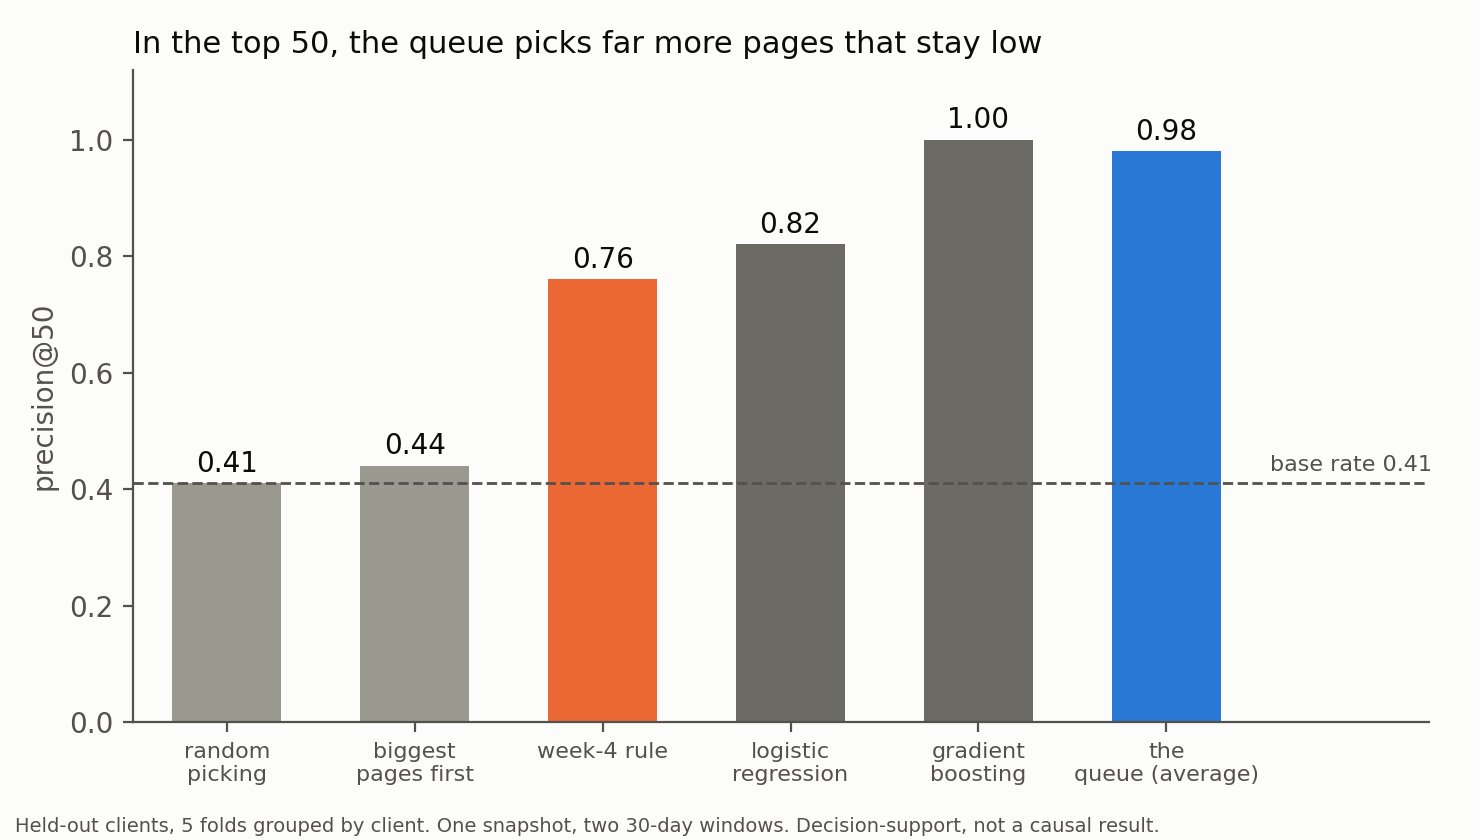

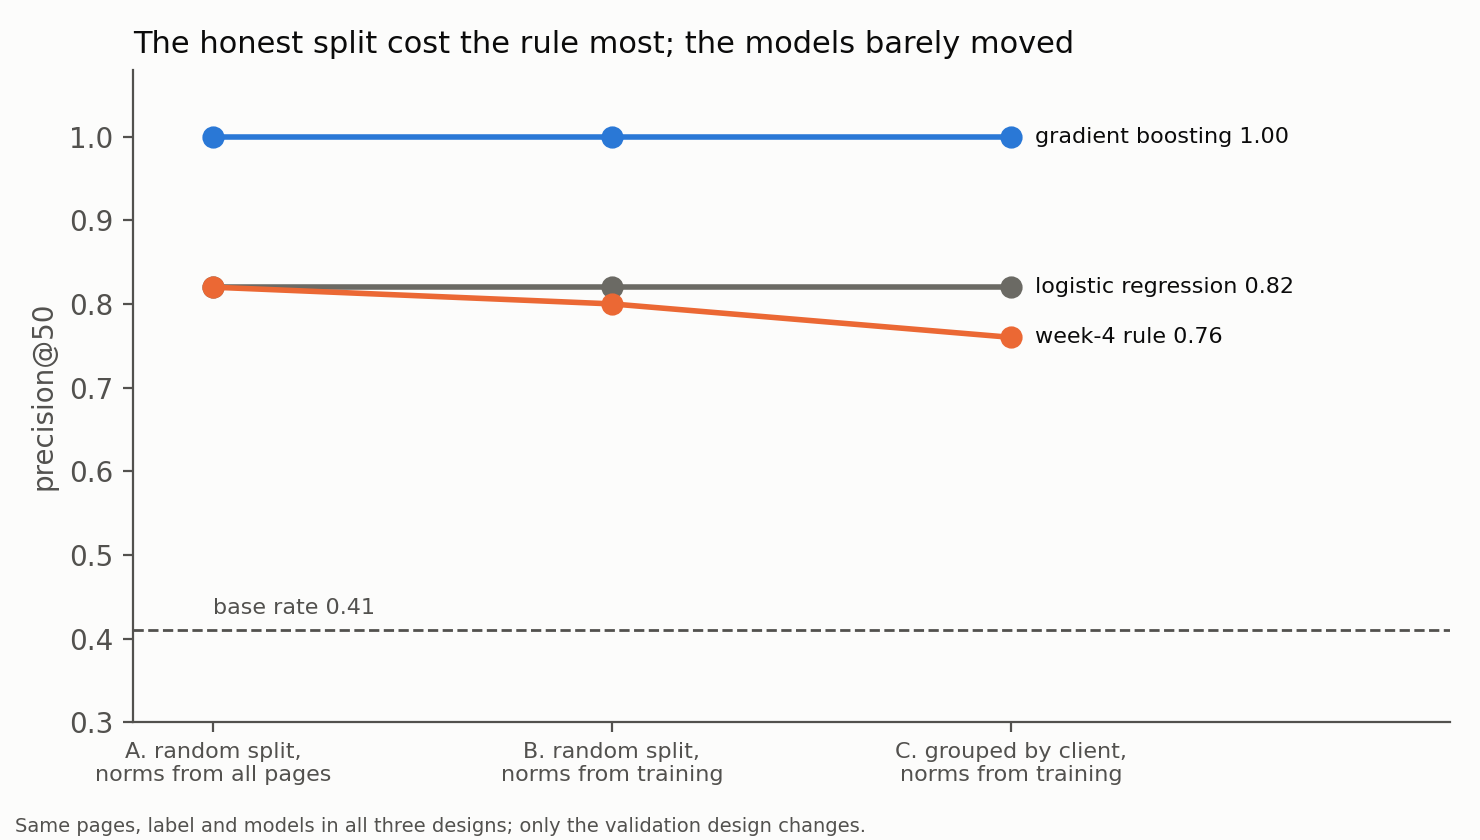

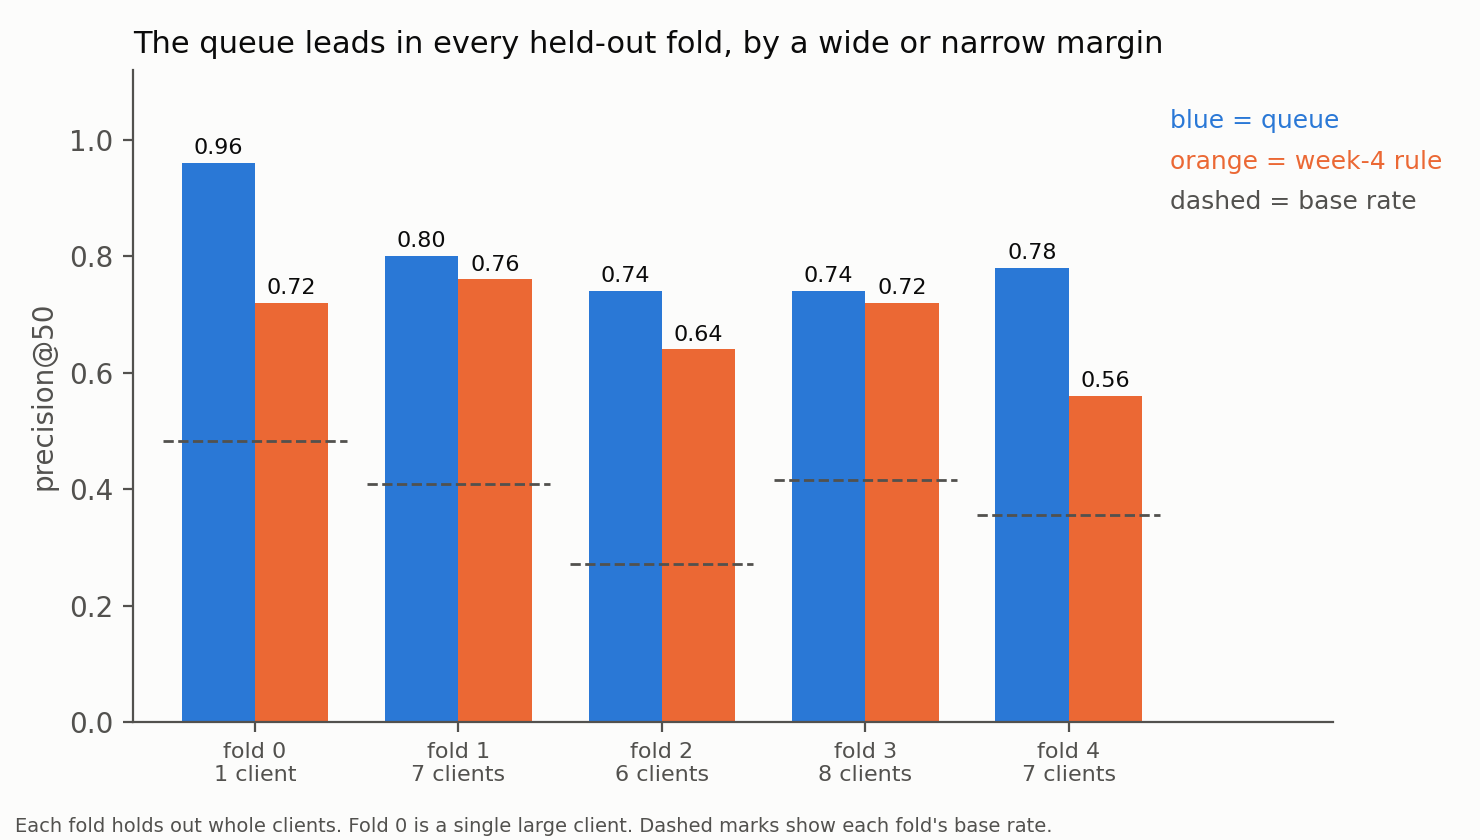

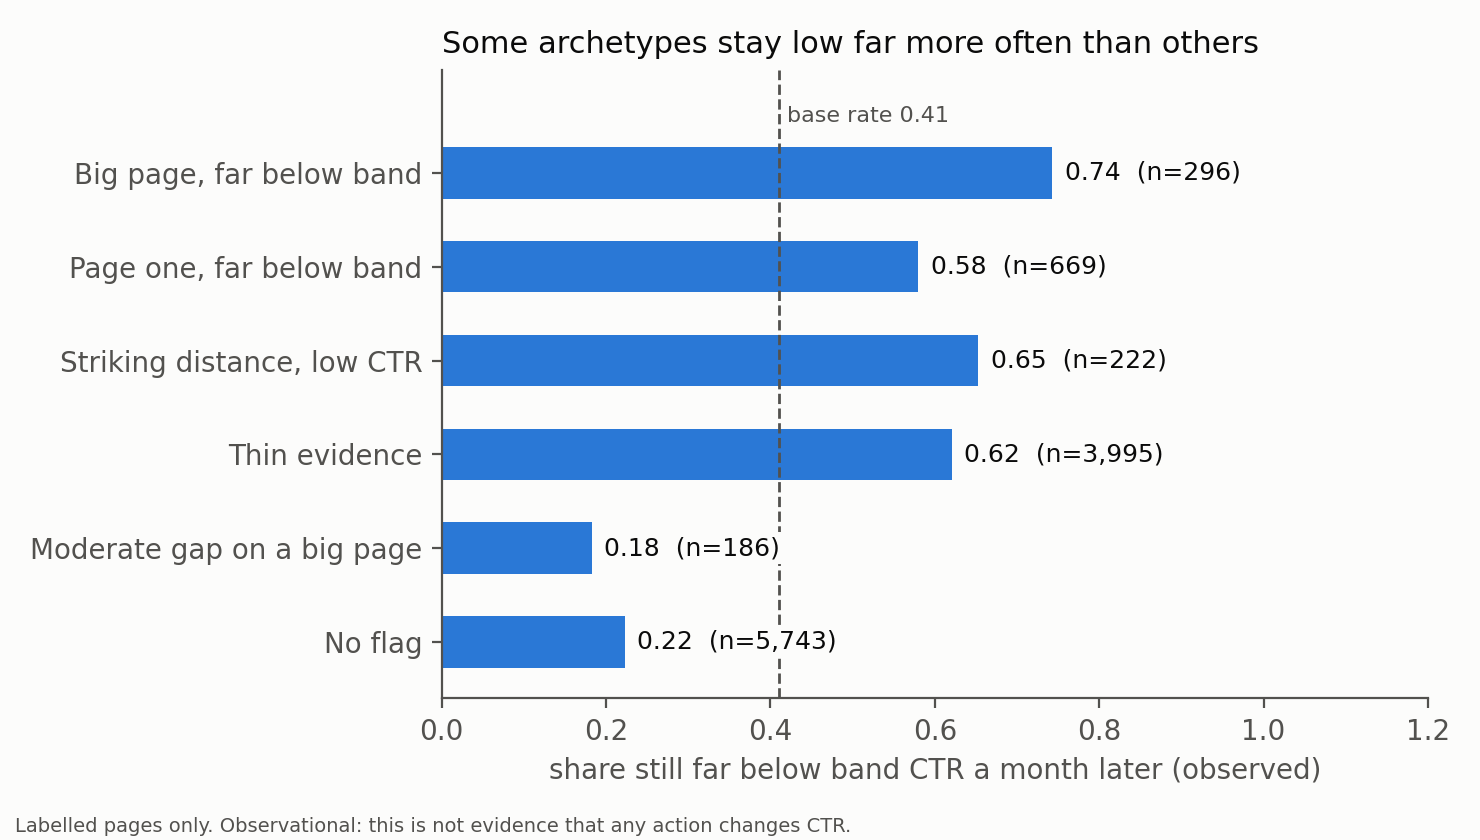

In [12]:
for n in ("fig_queue_vs_baselines", "fig_validation_designs", "fig_per_fold", "fig_archetype_low_later"):
    display(Image(f"work/figures/{n}.png", width=560))

## ML-12 · Show it: demo outline, social post, employer summary

*All three are generated from the metrics file, so they match the paper. Edit the wording into your own voice before you use them.*

In [13]:
m, M_ = M["main"], M
q_, r_ = m["average of both (the queue)"], m["week-4 rule"]
display(Markdown(f'''### 5-minute demo outline
1. **(0:00)** The decision: a reviewer has about 50 pages a week. Which 50? Show the review queue's top rows with their reason codes.
2. **(1:00)** The honest baseline: a one-line rule on CTR vs position band. precision@50 = {r_['p50']:.2f} against a base rate of {M_['data']['base_rate']:.2f}.
3. **(2:00)** The model and the split: whole clients held out. The queue reaches {q_['p50']:.2f} at the top 50 (AUC {q_['auc']:.2f} vs {r_['auc']:.2f} for the rule).
4. **(3:00)** The attack on my own work: leak tests (a deliberate leak gives AUC {M_['leakage']['add ctr_last (deliberate leak)']['auc']:.2f}, shuffled labels {M_['leakage']['shuffled labels']['auc']:.2f}) and where the model is wrong.
5. **(4:00)** The limits and the playbook: one client supplies {M_['errors']['top100_from_largest_client']} of the top 100, no causal claim, review steps only. Close on what I would check next.
'''))
display(Markdown(f'''### Social post (one finding, one chart, one method sentence)
Ranking pages by "CTR far below what its position normally earns" found {r_['p50']:.0%} of the right pages in the top 50. A model on held-out clients found {q_['p50']:.0%}, but one client supplies much of that list and a one-line volume rule gets close. Honest result: useful for deciding what to read first, not proof that any fix works. Chart + notebook in the paper.
'''))
display(Markdown(f'''### Employer 3-sentence summary
I built and validated a ranking model that tells a content reviewer which pages to look at first, using real search-performance data from {M_['data']['clients_total']} anonymized clients ({M_['data']['rows']:,} pages in the starter slice). On clients it had never seen, it placed {q_['p50']:.0%} of its top 50 picks among pages that stayed far below their position's normal CTR, against a {M_['data']['base_rate']:.0%} base rate and {r_['p50']:.0%} for my own simple rule. I then audited it for leakage, wrote down where it fails, and limited every claim to decision-support, because the data cannot show cause and effect.
'''))

### 5-minute demo outline
1. **(0:00)** The decision: a reviewer has about 50 pages a week. Which 50? Show the review queue's top rows with their reason codes.
2. **(1:00)** The honest baseline: a one-line rule on CTR vs position band. precision@50 = 0.76 against a base rate of 0.41.
3. **(2:00)** The model and the split: whole clients held out. The queue reaches 0.98 at the top 50 (AUC 0.79 vs 0.55 for the rule).
4. **(3:00)** The attack on my own work: leak tests (a deliberate leak gives AUC 1.00, shuffled labels 0.50) and where the model is wrong.
5. **(4:00)** The limits and the playbook: one client supplies 62 of the top 100, no causal claim, review steps only. Close on what I would check next.


### Social post (one finding, one chart, one method sentence)
Ranking pages by "CTR far below what its position normally earns" found 76% of the right pages in the top 50. A model on held-out clients found 98%, but one client supplies much of that list and a one-line volume rule gets close. Honest result: useful for deciding what to read first, not proof that any fix works. Chart + notebook in the paper.


### Employer 3-sentence summary
I built and validated a ranking model that tells a content reviewer which pages to look at first, using real search-performance data from 32 anonymized clients (30,000 pages in the starter slice). On clients it had never seen, it placed 98% of its top 50 picks among pages that stayed far below their position's normal CTR, against a 41% base rate and 76% for my own simple rule. I then audited it for leakage, wrote down where it fails, and limited every claim to decision-support, because the data cannot show cause and effect.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.